# Load libraries

In [113]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import os
from os import listdir
from os.path import isfile, join
import tifffile as tiff # you might have to install this with 'pip install tifffile'

# Print files in the current working directory (cwd)

In [114]:
folder = os.getcwd()
files = listdir(folder)

for i, f_i in enumerate(files):
    print(i, f_i)

0 03.tif
1 Load_and_plot_Tiff.ipynb
2 spectrum.txt


# Read and plot image file

In [115]:
img= tiff.imread(files[0])

In [116]:
# Convert images to arrays
img_array = np.array(img).astype('float64')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..1022].


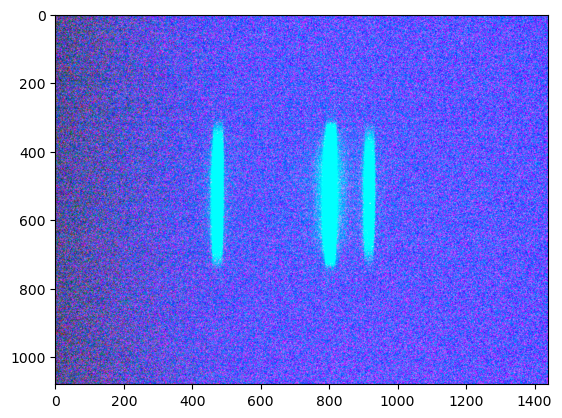

In [117]:
# Plot example image
plt.imshow(img, vmin=1000,vmax=0) 

# Plot linecut

In [118]:
print(np.shape(img_array))

(1080, 1440, 3)


In [119]:
y_max, x_max, c_max = np.shape(img_array)

x = np.linspace(0, x_max - 1, x_max)

y = 400

# chose color channel
c = 1

cts = img_array[y, :, c]

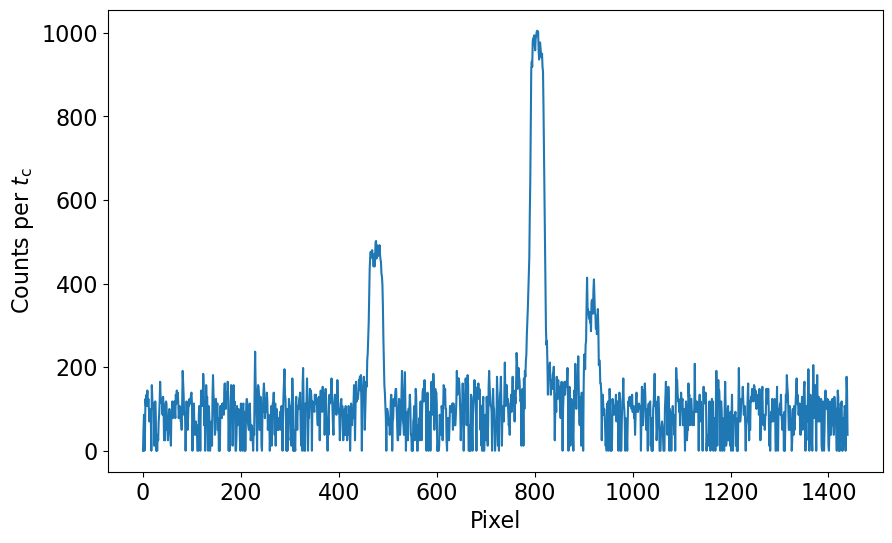

In [120]:
# Plot Data
plt.figure(
    num=1,
    figsize=(10,6),
    facecolor='white')
plt.xlabel(r'Pixel', fontsize=16)
plt.ylabel(r'Counts per $t_\mathrm{c}$', fontsize=16)
plt.plot(x, cts)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

In [121]:
print(len(cts))
print(len(x))

1440
1440


In [122]:
popt = np.loadtxt("../popt.txt")
k0 = popt[0]
b = popt[1]
d = popt[3]
p_cent = 720
print(b)
print(d)

-1.0
35.99999999999998


In [123]:
def lamda(pp, kk):
    return b * ((kk - k0) - (pp - p_cent) / d)

In [124]:
#must start with smallest wavelength
#must start with highest dial position

k = 190

data = np.loadtxt("spectrum.txt", delimiter=',')
start = 1440
if data.size == 0:
    start = 0
else:
    last = data[-1, 0]
    for i in range(len(x)):
        if lamda(i, k) > last:
            start = i
            break

sp = open("spectrum.txt", "a")

for i in range(start, len(x)):
    sp.write(str(lamda(x[i], k)))
    sp.write(", ")
    sp.write(str(cts[i]))
    sp.write("\n")
sp.close()

print(len(x) - start)

0
